# 03. The Daily Monitor

Guide 02 computed SVIX and the probability of a crash for one session.
This page is what happens when a replication is run every day without
anyone at the keyboard. A GitHub Actions workflow, `.github/workflows/deploy_pages.yml`,
wakes up at 14:30 UTC, pulls the previous session's settlements from
Databento, computes the row, appends it to the history, records the
history on a branch of its own, rebuilds this site, and publishes it. The
chart below is one point longer every morning.

**In this guide**

- The history, and the latest row.
- What the workflow does, step by step, and the places it can go
  wrong.
- Why the history lives on its own branch.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Image

import monitor
from settings import config

OUTPUT_DIR = Path(config("OUTPUT_DIR"))
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

history = monitor.load_history()
print(f"{len(history)} sessions, {history['date'].min().date()} to {history['date'].max().date()}")

30 sessions, 2026-09-14 to 2026-10-23


## The history

One row per session. The columns are documented in `src/monitor.py`; the
ones the chart uses are the 30-day SVIX (`svix_30`), the VIX close for
the same day from FRED, and the three probabilities of a 20% drop over
the expiration closest to one month: risk-neutral (`p_star_20`), the log
investor's (`p_log_20`), and the power-utility investor's with
$\gamma = 2$ (`p_power_20`).

In [2]:
cols = ["date", "days_used", "forward_near", "svix_30", "vix", "p_star_20", "p_log_20", "p_power_20", "p_star_10", "p_log_10"]
history[cols].tail(10).set_index("date").style.format({
    "forward_near": "{:,.2f}", "svix_30": "{:.2f}", "vix": "{:.2f}",
    "p_star_20": "{:.2%}", "p_log_20": "{:.2%}", "p_power_20": "{:.2%}", "p_star_10": "{:.2%}", "p_log_10": "{:.2%}",
})

,days_used,forward_near,svix_30,vix,p_star_20,p_log_20,p_power_20,p_star_10,p_log_10
date,,,,,,,,,
2026-10-12 00:00:00,18,"7,857.98",14.13,15.21,0.12%,0.08%,0.06%,0.65%,0.54%
2026-10-13 00:00:00,17,"7,855.76",14.18,15.27,0.10%,0.07%,0.05%,0.74%,0.62%
2026-10-14 00:00:00,16,"7,770.24",15.43,16.87,0.20%,0.14%,0.10%,1.00%,0.84%
2026-10-15 00:00:00,15,"7,791.00",15.05,16.46,0.20%,0.14%,0.10%,0.55%,0.44%
2026-10-16 00:00:00,45,"7,704.24",17.71,19.99,1.21%,0.80%,0.54%,4.02%,3.19%
2026-10-19 00:00:00,42,"7,734.51",16.64,18.44,1.01%,0.68%,0.47%,3.70%,2.99%
2026-10-20 00:00:00,41,"7,755.26",15.89,17.31,0.80%,0.54%,0.37%,3.31%,2.70%
2026-10-21 00:00:00,40,"7,800.25",15.37,16.68,0.67%,0.45%,0.31%,3.19%,2.63%
2026-10-22 00:00:00,39,"7,704.50",17.29,19.03,1.00%,0.68%,0.47%,3.73%,3.03%


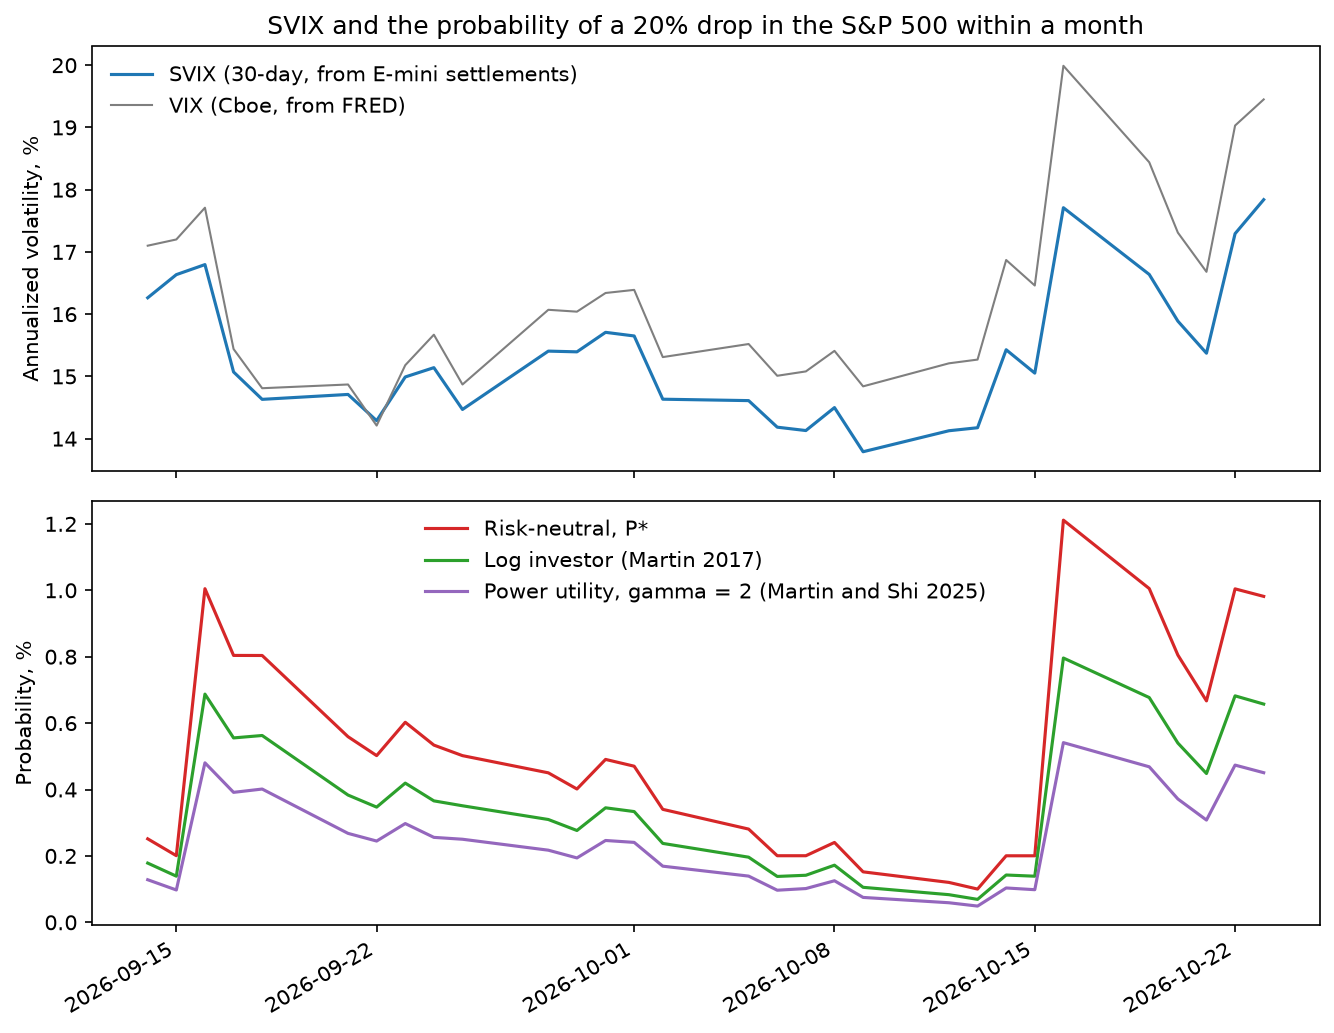

In [3]:
Image(filename=str(OUTPUT_DIR / "svix_monitor.png"))

The same chart, interactive, is the site's chart page, built by
`src/monitor_chart.py` from this history.

SVIX sits a little below the VIX. Both are annualized volatilities read
off the same options, but the VIX weights each strike by $1/K^2$ and
SVIX weights them equally, so the VIX leans harder on the put wing; the
gap is a measure of how steep the smirk is. The probabilities move with
the smile too, and the risk-neutral one is always the largest: it charges
for crash states at their marginal utility.

## What the workflow does

`uv run doit monitor` is the whole update. The task pulls the latest
session (cheap: 19 MB, $0.00, a minute or two), computes its row if the
history does not have it, appends it, and redraws the charts. Run it on
your laptop and it does the same thing. `uv run doit backfill` is the same
computation over a range of dates, run once by hand so the chart has a
history behind it; on Actions a second workflow does that, started from
the Actions tab with a start date. The daily workflow adds the parts that
make the update unattended:

1. **A schedule.** A `cron` line under `on: schedule:` starts the run
   every morning, after CME's final settlements of the previous evening
   have reached Databento. GitHub's cron runs in UTC; the five fields are
   minute, hour, day of month, month, and day of week.
2. **A secret.** The pull needs your Databento key. It lives in the
   repository's secret store (Settings → Secrets and variables → Actions),
   and the step that needs it reads it from there through the `secrets`
   context. It is never in the file, never in a commit, never in the log.
3. **An environment.** `astral-sh/setup-uv` installs `uv`; `uv run doit`
   then installs Python 3.12 and the locked dependencies from `uv.lock`,
   the same versions as on your laptop.
4. **A ledger.** The updated history is committed to the `monitor-history`
   branch from a second working directory (`git worktree`): one small
   commit a day, the day's row. A push to that branch does not start the
   workflow, which listens to pushes on `main` only.
5. **A deploy.** The built `docs/` folder is force-pushed as a single
   orphan commit on the `gh-pages` branch, which GitHub Pages serves.

Three places it goes wrong, in our experience. A workflow that commits
its output to `main` retriggers itself on every run, forever, unless each
push says `[skip ci]`; keeping output off `main` removes the problem. A
deploy that does not `git clean -fdx` first carries `_data/` and `.venv/`
into the published site. And a data source can be down: Databento and FRED
both time out now and then. The pulls retry server and network errors,
waiting longer each time, for about eight minutes. If a source is still
down after that, the step after the pull sees the marker the pull left
and ends the run with a warning, not a failure: yesterday's site stays
up, and tomorrow's pull, which covers the trailing week, fills the gap.
Any other failure is a bug and fails the run.

## Why the history lives on its own branch

Everything else the pipeline produces is regenerated from source: pull
again, compute again, same answer. The history is different. Each row
costs a session's pull, and a year of them would cost a year of pulls, so
the monitor keeps what it has computed. Not on `main`, though: `main`
holds source code, and nothing a run produces belongs there. The workflow
keeps the one file, `svix_monitor_history.csv`, on a branch of its own,
`monitor-history`. Each morning it restores the file from there into
`_output/`, appends the new sessions, and commits the result back as one
small commit, so the branch is the ledger of the series, one line a day,
and `git log -p` on it shows the chart being built point by point. The
site itself sits on `gh-pages` as a single commit that each run replaces.
The daily run adds one session. The history behind it comes from a
backfill, the same computation over a range of dates, run once by hand;
if the engine ever changes, the same backfill rebuilds the history.

In [4]:
latest = history.iloc[-1]
HTML(
    f"<p>As of <b>{latest['date']:%A, %B %d, %Y}</b>: SVIX {latest['svix_30']:.1f}, VIX {latest['vix']:.1f}; "
    f"the options market prices a 20% drop over the next {int(latest['days_used'])} days at "
    f"<b>{100 * latest['p_star_20']:.2f}%</b> risk-neutral, which a log investor who holds the market reads as "
    f"<b>{100 * latest['p_log_20']:.2f}%</b>.</p>"
)